# WP12 — Mevcut Qwen3 modeli ön kontrolü
**Bellek kapısında duruldu.** Notebook gerçek kayıtları gösterir; model yükleme, çıkarım, indirme veya eğitim içermez. Kaynaklı açıklama/insan incelemesi kuralları değişmedi.

,Ölçüm,Boş RAM GiB,RAM kullanım %,GPU boş MiB,Bellek kapısı
0,2026-11-08T03:24:53.806012+03:00,0.934158,87.4,3935,False


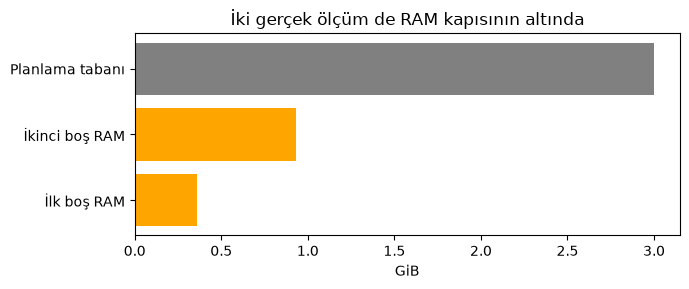

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();Q=ROOT/'reports/qa/WP12/local_llm_pilot_v1'
p=json.loads((Q/'preflight.json').read_text(encoding='utf-8'));m=json.loads((Q/'model_identity.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Ölçüm':p['captured_at'],'Boş RAM GiB':p['RAM']['available']/2**30,'RAM kullanım %':p['RAM']['percent'],'GPU boş MiB':p['GPU']['free_MiB'],'Bellek kapısı':p['memory_gate_passed']}]))
fig,ax=plt.subplots(figsize=(7,3));ax.barh(['İlk boş RAM','İkinci boş RAM','Planlama tabanı'],[386510848/2**30,p['RAM']['available']/2**30,3],color=['orange','orange','grey']);ax.set_xlabel('GiB');ax.set_title('İki gerçek ölçüm de RAM kapısının altında')
F=ROOT/'reports/figures/WP12/local_llm_pilot_v1';F.mkdir(parents=True,exist_ok=True);fig.tight_layout();fig.savefig(F/'memory_gate.png',dpi=150);plt.show()

**Yorum:** Bellek anlık değişiyor; her iki ölçüm de3GiB tabanının altında. Bu bir üretici sığma garantisi değildir. Mevcut4B modeli bu durumda zorla yüklemiyoruz.

In [2]:
print(p['client_version_check']['stdout']);print('Tam model manifest digest:',m['manifest_digest'])
display(pd.DataFrame(m['layers'])[['digest','size','actual_size','digest_valid','size_valid']])
display(pd.DataFrame(p['loopback_metadata_attempts']))


Tam model manifest digest: sha256:0edcdef34593eac1aa2be9c7d06c432dcf81945adca5eca2f27662c18f168ba0


,digest,size,actual_size,digest_valid,size_valid
0,sha256:b72accf9724e93698c57cbd3b1af2d3341b3d05...,487,487,True,True
1,sha256:85e4a5b7b8ef0e48af0e8658f5aaab9c2324c76...,2497280480,2497280480,True,True
2,sha256:eade0a07cac7712787bbce23d12f9306adb4781...,1379,1379,True,True
3,sha256:d18a5cc71b84bc4af394a31116bd3932b42241d...,11338,11338,True,True
4,sha256:0914c7781e001948488d937994217538375b4fd...,119,119,True,True


,method,url,error_type,error
0,GET,http://127.0.0.1:11434/api/version,URLError,<urlopen error [WinError 10013] An attempt was...
1,GET,http://127.0.0.1:11434/api/tags,URLError,<urlopen error [WinError 10013] An attempt was...


**Yorum:** İstemci0.40.6 ve modelin gerçek dosya hash'leri doğrulandı. Servis sürümü ve JSON Schema API desteği doğrulanamadı: socket erişim hatası alındı; bu, servisin yokluğunun kanıtı değildir. Akışla ağırlık hash'i almak inference için modeli yüklemek değildir.

In [3]:
records=pd.DataFrame(json.loads((Q/'scenario_execution_status.json').read_text(encoding='utf-8')))
display(records.groupby(['scenario_id','status'],as_index=False).agg(planlanan_tekrar=('repeat','count')))
display(records[['status','LLM_output','schema_result','human_semantic_review']].head(3))
print('Planlanan',len(records),'Çalıştırılan',0)

Planlanan 57 Çalıştırılan 0


,scenario_id,status,planlanan_tekrar
0,S01,NOT_RUN_MEMORY_GATE,3
1,S02,NOT_RUN_MEMORY_GATE,3
2,S03,NOT_RUN_MEMORY_GATE,3
3,S04,NOT_RUN_MEMORY_GATE,3
4,S05,NOT_RUN_MEMORY_GATE,3
5,S06,NOT_RUN_MEMORY_GATE,3
6,S07,NOT_RUN_MEMORY_GATE,3
7,S08,NOT_RUN_MEMORY_GATE,3
8,S09,NOT_RUN_MEMORY_GATE,3
9,S10,NOT_RUN_MEMORY_GATE,3


,status,LLM_output,schema_result,human_semantic_review
0,NOT_RUN_MEMORY_GATE,None,None,NOT_PERFORMED_NO_OUTPUT
1,NOT_RUN_MEMORY_GATE,None,None,NOT_PERFORMED_NO_OUTPUT
2,NOT_RUN_MEMORY_GATE,None,None,NOT_PERFORMED_NO_OUTPUT


**Yorum:**19×3 planın tamamı NOT_RUN_MEMORY_GATE. Null kalite/şema sonuçları başarı sıfırı değildir. Gerçek yanıt bulunmadığından insan semantik incelemesi veya otomatik yayın yoktur. reported_in_PDF ile predicted_by_GNN alanları için sahte açıklama üretilmedi.

In [4]:
for name in ['test_wp12_llm_contract_audit.txt','test_wp12_llm_preflight_audit.txt']:
 print(name);print((Q/name).read_text(encoding='utf-8'))

test_wp12_llm_contract_audit.txt
test_01_all44_exact_spans (test_wp12_llm_contract.ContractTests.test_01_all44_exact_spans) ... ok
test_02_pending_not_semantic_pass (test_wp12_llm_contract.ContractTests.test_02_pending_not_semantic_pass) ... ok
test_03_missing_evidence (test_wp12_llm_contract.ContractTests.test_03_missing_evidence) ... ok
test_04_unknown_evidence (test_wp12_llm_contract.ContractTests.test_04_unknown_evidence) ... ok
test_05_unselected_real_evidence (test_wp12_llm_contract.ContractTests.test_05_unselected_real_evidence) ... ok
test_06_no_model_branch (test_wp12_llm_contract.ContractTests.test_06_no_model_branch) ... ok
test_07_no_model_or_label_fields (test_wp12_llm_contract.ContractTests.test_07_no_model_or_label_fields) ... ok
test_08_class_scope_not_direct (test_wp12_llm_contract.ContractTests.test_08_class_scope_not_direct) ... ok
test_09_class_context_required (test_wp12_llm_contract.ContractTests.test_09_class_context_required) ... ok
test_10_renal_exception_requi

**Yorum:**24 kaynak sözleşmesi ve6 bellek kapısı testi offline geçti. Bunlar yerel Ollama JSON Schema desteğini veya LLM kalitesini doğrulamaz. Kaynak/model sonuçları korunur. RAM ve API erişimi uygun hale gelene kadar bu aşamada durulur; WP13 başlamadı.